# Regularización: curar el overfitting

El Lab 09 diagnosticó el problema: el overfitting son pesos enormes memorizando el ruido. La cura no es quitar features a mano, sino castigar los pesos grandes dentro del propio costo. Este lab va en dos partes: primero las piezas (cómo cambian el costo y el gradiente, lado a lado en regresión lineal y logística) y al final los ejemplos completos.

### La penalización

Al costo $J$ se le suma un castigo proporcional a los pesos al cuadrado:

$$J_{reg}(w,b) = J(w,b) + \frac{\lambda}{2m} \sum_{j=1}^{n} w_j^2$$

Dos detalles que importan:

- **$b$ no se penaliza** (la suma empieza en $j = 1$): el sesgo solo desplaza, no curva ni memoriza, así que se deja libre.
- **$\lambda$ es la perilla**: con $\lambda = 0$ no hay cura; con $\lambda$ gigante todos los pesos se van a cero y caen en underfitting. El punto bueno está en medio y se busca probando valores.

### La fórmula nueva del costo, lado a lado

Lineal: $J_{reg} =$ MSE $+ (\lambda/2m)$ por la suma de $w_j^2$. Logística: $J_{reg} =$ log-loss $+ (\lambda/2m)$ por la suma de $w_j^2$. El término extra es idéntico; solo cambia la $J$ base. En ambos, $b$ queda fuera de la suma.

In [ ]:
import numpy as np

def compute_cost_reg_linear(X, y, w, b, lam):
    """
    J MSE regularizada con bucles explícitos. b no se penaliza.
    """
    m, n = X.shape
    suma = 0.0
    for i in range(m):
        suma = suma + (np.dot(X[i], w) + b - y[i]) ** 2
    j_plain = suma / (2 * m)
    castigo = 0.0
    for j in range(n):
        castigo = castigo + w[j] ** 2
    castigo = (lam / (2 * m)) * castigo
    return j_plain, castigo, j_plain + castigo

def compute_cost_reg_logistic(X, y, w, b, lam):
    """
    J logarítmica regularizada con bucles explícitos. b no se penaliza.
    """
    m, n = X.shape
    suma = 0.0
    for i in range(m):
        f = 1 / (1 + np.exp(-(np.dot(X[i], w) + b)))
        suma = suma + (-(y[i] * np.log(f) + (1 - y[i]) * np.log(1 - f)))
    j_plain = suma / m
    castigo = 0.0
    for j in range(n):
        castigo = castigo + w[j] ** 2
    castigo = (lam / (2 * m)) * castigo
    return j_plain, castigo, j_plain + castigo

# SOLO PARA ILUSTRAR LA NUEVA FORMULA:

# Paso 1: J contra J_reg con pesos fijos (lineal: recta en 4 puntos; LR: juguete 4 puntos)
X_lin = np.array([[1.0], [2.0], [3.0], [4.0]])
y_lin = np.array([1.0, 2.0, 2.5, 4.0])
jp, pen, jr = compute_cost_reg_linear(X_lin, y_lin, np.array([1.0]), 0.0, 4.0)
print(f"lineal: J = {jp:.3f} + castigo {pen:.3f} = J_reg {jr:.3f}")
X_toy = np.array([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
y_toy = np.array([0, 0, 1, 1])
jp, pen, jr = compute_cost_reg_logistic(X_toy, y_toy, np.array([1.0, 1.0]), -1.0, 4.0)
print(f"logística: J = {jp:.3f} + castigo {pen:.3f} = J_reg {jr:.3f}")
# Paso 1b: Ajustes que usa el ejemplo final
# Mismos datos curvos del Lab 09, features grado 12 estandarizadas
rng = np.random.default_rng(11)
x = np.linspace(0, 5, 40)
y = 0.5 * x ** 2 - 2 * x + 1 + rng.normal(0, 0.8, 40)
P = np.column_stack([x ** i for i in range(13)])
m = P.shape[0]
mu_poly = np.zeros(12)
for i in range(m):
    mu_poly = mu_poly + P[i, 1:]
mu_poly = mu_poly / m
sg_poly = np.zeros(12)
for i in range(m):
    sg_poly = sg_poly + (P[i, 1:] - mu_poly) ** 2
sg_poly = np.sqrt(sg_poly / m)
P_feat = (P[:, 1:] - mu_poly) / sg_poly
Pn = np.column_stack([np.ones(m), P_feat])
D = np.eye(13)
D[0, 0] = 0.0
pesos = {}
for lam in [0, 1, 100]:
    wb = np.linalg.solve(np.dot(Pn.T, Pn) + lam * D, np.dot(Pn.T, y))
    pesos[lam] = wb
    jp, pen, jr = compute_cost_reg_linear(P_feat, y, wb[1:], float(wb[0]), lam)
    print(f"ajuste lambda = {lam:3d}: J = {jp:.3f} + castigo {pen:.3f} = J_reg {jr:.3f} | peso mayor = {np.abs(wb[1:]).max():.1f}")


lineal: J = 0.031 + castigo 0.500 = J_reg 0.531
logística: J = 0.503 + castigo 1.000 = J_reg 1.503
ajuste lambda =   0: J = 0.140 + castigo 0.000 = J_reg 0.140 | peso mayor = 1439365.8
ajuste lambda =   1: J = 0.198 + castigo 0.052 = J_reg 0.250 | peso mayor = 1.3
ajuste lambda = 100: J = 0.465 + castigo 0.103 = J_reg 0.567 | peso mayor = 0.1


### La fórmula nueva del gradiente, lado a lado

Al derivar aparece el mismo sumando extra en ambos modelos: $(\lambda/m) \cdot w_j$ para $j \geq 1$, y cero extra para $b$. Cada peso se encoge un poco en cada iteración (decaimiento): solo sobreviven los pesos que el error realmente necesita. La única diferencia entre lineal y logística es el gradiente base del que parte cada uno.

In [9]:
import numpy as np

def compute_gradient_reg_linear(X, y, w, b, lam):
    """
    Gradiente MSE regularizado con bucles explícitos. b libre del castigo.
    """
    m, n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0.0
    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err * X[i, j]
        dj_db = dj_db + err
    for j in range(n):
        dj_dw[j] = dj_dw[j] / m + (lam / m) * w[j]
    return dj_dw, dj_db / m

def compute_gradient_reg_logistic(X, y, w, b, lam):
    """
    Gradiente logístico regularizado con bucles explícitos. b libre del castigo.
    """
    m, n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0.0
    for i in range(m):
        err = 1 / (1 + np.exp(-(np.dot(X[i], w) + b))) - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err * X[i, j]
        dj_db = dj_db + err
    for j in range(n):
        dj_dw[j] = dj_dw[j] / m + (lam / m) * w[j]
    return dj_dw, dj_db / m

# Paso 2: Gradiente con y sin castigo sobre pesos fijos
X_lin = np.array([[1.0], [2.0], [3.0], [4.0]])
y_lin = np.array([1.0, 2.0, 2.5, 4.0])
g0, _ = compute_gradient_reg_linear(X_lin, y_lin, np.array([1.0]), 0.0, 0.0)
g1, _ = compute_gradient_reg_linear(X_lin, y_lin, np.array([1.0]), 0.0, 4.0)
print(f"lineal: grad sin castigo {g0[0]:.3f} | con castigo {g1[0]:.3f} (extra {(g1[0] - g0[0]):.3f})")
X_toy = np.array([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
y_toy = np.array([0, 0, 1, 1])
h0, _ = compute_gradient_reg_logistic(X_toy, y_toy, np.array([1.0, 1.0]), -1.0, 0.0)
h1, _ = compute_gradient_reg_logistic(X_toy, y_toy, np.array([1.0, 1.0]), -1.0, 4.0)
print(f"logística: grad sin castigo {np.round(h0, 3)} | con castigo {np.round(h1, 3)} (extra {np.round(h1 - h0, 3)})")
print("El sumando extra es el mismo término en ambas.")

lineal: grad sin castigo 0.375 | con castigo 1.375 (extra 1.000)
logística: grad sin castigo [-0.192  0.058] | con castigo [0.808 1.058] (extra [1. 1.])
El sumando extra es el mismo término en ambas.


### De las fórmulas a los ejemplos

Con el costo y el gradiente programados, lo que sigue son los ejemplos completos: las curvas domadas en regresión lineal y la frontera que se vuelve círculo en logística.

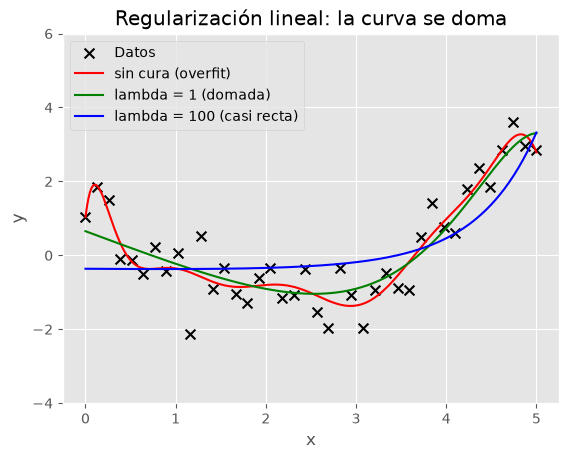

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

# Ejemplo final 1 (lineal): las 3 curvas domadas con los pesos del mini-lab A
xs = np.linspace(0, 5, 300)
Ps = np.column_stack([xs ** i for i in range(13)])
Psn = np.column_stack([np.ones(len(xs)), (Ps[:, 1:] - mu_poly) / sg_poly])
plt.scatter(x, y, marker='x', c='k', s=50, label='Datos')
for lam, color, nombre in [(0, 'r', 'sin cura (overfit)'), (1, 'g', 'lambda = 1 (domada)'),
                           (100, 'b', 'lambda = 100 (casi recta)')]:
    plt.plot(xs, np.dot(Psn, pesos[lam]), c=color, label=nombre)
plt.title("Regularización lineal: la curva se doma")
plt.xlabel("x")
plt.ylabel("y")
plt.ylim(-4, 6)
plt.legend()
plt.show()

lambda =  0: exactitud train = 97% | peso mayor = 4.1 | longitud frontera = 25.2
lambda =  5: exactitud train = 92% | peso mayor = 0.6 | longitud frontera = 10.4
lambda = 50: exactitud train = 87% | peso mayor = 0.2 | longitud frontera = 11.3


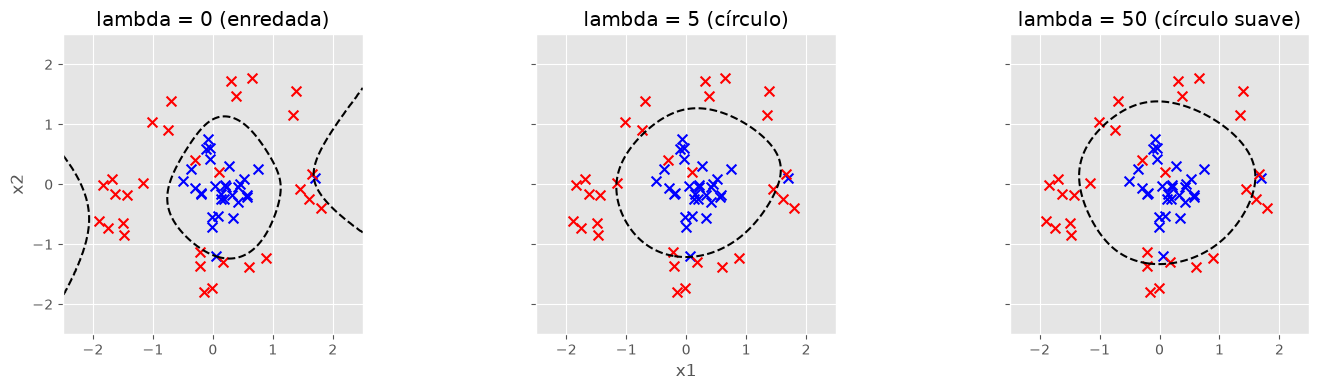

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

# Ejemplo final 2 (LR): anillo con más ruido (dispersión + etiquetas volteadas)
rng = np.random.default_rng(9)
n = 30
th = rng.uniform(0, 2 * np.pi, n)
good = np.column_stack([rng.normal(0.5, 0.30, n) * np.cos(th), rng.normal(0.5, 0.30, n) * np.sin(th)])
th2 = rng.uniform(0, 2 * np.pi, n)
bad = np.column_stack([rng.normal(1.6, 0.30, n) * np.cos(th2), rng.normal(1.6, 0.30, n) * np.sin(th2)])
bad[0] = [0.1, 0.2]
bad[1] = [-0.3, 0.4]
good[0] = [1.7, 0.1]
X = np.vstack([good, bad])
y = np.array([0] * n + [1] * n)

def poly_features(X, d):
    """Expande a potencias hasta grado d (truco del Lab 05)."""
    cols = [np.ones(len(X))]
    for i in range(1, d + 1):
        for j in range(i + 1):
            cols.append((X[:, 0] ** (i - j)) * (X[:, 1] ** j))
    return np.column_stack(cols)

# Paso 3: Grado 8 con lambda 0, 5 y 50 (máscara: el sesgo no se penaliza)
P = poly_features(X, 8)
m = len(X)
mu8 = np.zeros(P.shape[1] - 1)
for i in range(m):
    mu8 = mu8 + P[i, 1:]
mu8 = mu8 / m
sg8 = np.zeros(P.shape[1] - 1)
for i in range(m):
    sg8 = sg8 + (P[i, 1:] - mu8) ** 2
sg8 = np.sqrt(sg8 / m)
Pn = np.column_stack([np.ones(m), (P[:, 1:] - mu8) / sg8])
mask = np.ones(Pn.shape[1])
mask[0] = 0.0

def longitud_frontera(cs):
    """Longitud total de la curva de nivel: mide qué tan enredada está."""
    total = 0.0
    for path in cs.get_paths():
        v = path.vertices
        for k in range(len(v) - 1):
            total = total + abs(v[k + 1, 0] - v[k, 0]) + abs(v[k + 1, 1] - v[k, 1])
    return total

g = np.linspace(-2.5, 2.5, 200)
G1, G2 = np.meshgrid(g, g)
Pm = poly_features(np.column_stack([G1.ravel(), G2.ravel()]), 8)
Pnm = np.column_stack([np.ones(len(Pm)), (Pm[:, 1:] - mu8) / sg8])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, lam, title in zip(axes, [0, 5, 50],
                           ["lambda = 0 (enredada)", "lambda = 5 (círculo)",
                            "lambda = 50 (círculo suave)"]):
    w = np.zeros(Pn.shape[1])
    for _ in range(8000):
        err = sigmoid(np.dot(Pn, w)) - y
        w = w - 0.1 * (np.dot(Pn.T, err) / m + (lam / m) * mask * w)
    pred = (sigmoid(np.dot(Pn, w)) >= 0.5).astype(int)
    acc = float(np.sum(pred == y) / len(y))
    Z = sigmoid(np.dot(Pnm, w)).reshape(G1.shape)
    ax.scatter(good[:, 0], good[:, 1], marker='x', c='b', s=50)
    ax.scatter(bad[:, 0], bad[:, 1], marker='x', c='r', s=50)
    cs = ax.contour(G1, G2, Z, levels=[0.5], colors='k', linestyles='--')
    print(f"lambda = {lam:2d}: exactitud train = {acc:.0%} | peso mayor = {np.abs(w[1:]).max():.1f} | longitud frontera = {longitud_frontera(cs):.1f}")
    ax.set_title(title)
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_aspect('equal')
axes[1].set_xlabel("x1")
axes[0].set_ylabel("x2")
plt.tight_layout()
plt.show()

### Cómo elegir lambda en la práctica

No hay fórmula mágica: se prueban varios valores ($0.01, 0.1, 1, 10, 100$) y se elige el que rinda mejor en datos de validación (ni train ni test final). Muy chico y no cura; muy grande y aplasta hasta lo útil. Cabe recordar: $b$ nunca entra al castigo.

### Cierre del hilo 09–10

- El Lab 09 diagnosticó: overfitting son pesos enormes memorizando ruido.
- Este lab curó: penalizar los pesos con lambda encoge lo innecesario y conserva lo útil.
- Funciona igual en regresión lineal y en logística: mismo término, misma idea.